In [ ]:
!pip install fastapi uvicorn nest-asyncio pydantic tldextract beautifulsoup4 scikit-learn python-whois dnspython requests
!npm install -g localtunnel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.4/106.4 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 15.9 MB/s eta 0:00:00
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
added 22 packages in 5s
⠦
⠦3 packages are looking for funding
⠦  run `npm fund` for details
⠦npm notice
npm notice New major version of npm available! 10.8.2 -> 12.0.2
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.0.2
npm notice To update run: npm install -g npm@12.0.2
npm notice
⠦

In [ ]:
import pandas as pd
import numpy as np
import pickle
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("TensorFlow Version:", tf.__version__)

# 1. LOAD FULL DATASET
dataset_url = 'https://raw.githubusercontent.com/biggmanuel/URL-and-Content-Hybrid-Deep/refs/heads/main/dataset_full.csv'
print(f"\nDownloading dataset from: {dataset_url}")
df = pd.read_csv(dataset_url)

# 2. ISOLATE ALL 111 FEATURES (LEXICAL + NETWORK/CONTENT)
X = df.iloc[:, :-1].values
y = df['phishing'].values
feature_count = X.shape[1]

print(f"Model will now learn from the full {feature_count}-feature Hybrid set.")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. BUILD THE FEEDFORWARD NEURAL NETWORK (FNN)
tf.random.set_seed(42)
model = Sequential([
    Dense(128, activation='relu', input_shape=(feature_count,)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 4. TRAIN THE MODEL
print("\n--- Starting Model Training ---")
history = model.fit(
    X_train_scaled, y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_test_scaled, y_test),
    verbose=1
)

# 5. SAVE ARTIFACTS
model.save('fnn_phishing_model.h5')
with open('scaler.pkl', 'wb') as handle:
    pickle.dump(scaler, handle, protocol=pickle.HIGHEST_PROTOCOL)

with open('feature_count.txt', 'w') as f:
    f.write(str(feature_count))

print("\n✅ 111-Feature Hybrid Model and Scaler successfully saved!")

TensorFlow Version: 2.20.0

Model will now learn from the full 111-feature Hybrid set.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



--- Starting Model Training ---
Epoch 1/20
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9257 - loss: 0.1827 - val_accuracy: 0.9408 - val_loss: 0.1429
Epoch 2/20
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9415 - loss: 0.1477 - val_accuracy: 0.9480 - val_loss: 0.1318
Epoch 3/20
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9463 - loss: 0.1376 - val_accuracy: 0.9501 - val_loss: 0.1248
Epoch 4/20
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9492 - loss: 0.1323 - val_accuracy: 0.9513 - val_loss: 0.1222
Epoch 5/20
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9506 - loss: 0.1282 - val_accuracy: 0.9539 - val_loss: 0.1191
Epoch 6/20
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9521 - loss: 0.1258 - val_accuracy: 0.9540 - val_loss: 0.1186
Epoch 7/20
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9531 - loss: 0.1229 - val_accuracy: 0.9549 - val_loss: 0.1171
Epoch 8/20
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - 


✅ 111-Feature Hybrid Model and Scaler successfully saved!


In [ ]:
%%writefile main.py
from fastapi import FastAPI
from pydantic import BaseModel
import tensorflow as tf
import pickle
import numpy as np
import re
import requests
import whois
import dns.resolver
import time
from datetime import datetime
from urllib.parse import urlparse
from fastapi.middleware.cors import CORSMiddleware

app = FastAPI()
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"]
)

# Load Artifacts
model = tf.keras.models.load_model('fnn_phishing_model.h5')
with open('scaler.pkl', 'rb') as handle:
    scaler = pickle.load(handle)

THRESHOLD = 0.50

# Firebase Database Logging Endpoint
FIREBASE_LOG_URL = "https://url-and-content-hybrid-deep-default-rtdb.firebaseio.com/threats_log.json"

class Payload(BaseModel):
    url: str

def count_chars(text):
    if not text: return [-1] * 17
    return [text.count(ch) for ch in ['.', '-', '_', '/', '?', '=', '@', '&', '!', ' ', '~', ',', '+', '*', '#', '$', '%']]

def extract_111_features(url: str):
    clean_url = url.strip().lower()
    if not clean_url.startswith('http://') and not clean_url.startswith('https://'):
        clean_url = 'https://' + clean_url

    parsed = urlparse(clean_url)
    netloc = parsed.netloc
    if netloc.startswith('www.'): netloc = netloc[4:]

    # --- 1 to 97: LEXICAL FEATURES ---
    f_url = count_chars(clean_url)
    f_url.extend([clean_url.count('.') - 1 if clean_url.count('.') > 0 else 0, len(clean_url)])

    f_dom = count_chars(netloc)
    f_dom.extend([sum(1 for v in netloc if v in 'aeiou'), len(netloc)])
    f_dom.extend([1 if re.search(r'\d+\.\d+\.\d+\.\d+', netloc) else 0, 1 if 'server' in netloc or 'client' in netloc else 0])

    path = parsed.path

    # NORMALIZATION FIX: Strip redundant root trailing slashes
    if path == '/':
        path = ''

    if '/' in path:
        directory, file = path.rsplit('/', 1)[0] + '/', path.rsplit('/', 1)[1]
    else:
        directory, file = '', path

    f_dir = count_chars(directory)
    f_dir.append(len(directory) if directory else -1)

    f_file = count_chars(file)
    f_file.append(len(file) if file else -1)

    query = parsed.query
    f_par = count_chars(query)
    f_par.extend([len(query) if query else -1, 1 if query and '.' in query else (0 if query else -1), query.count('=') if query else -1])

    lexical_features = f_url + f_dom + f_dir + f_file + f_par + [1 if re.search(r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}', clean_url) else 0]

    # --- 98 to 111: NETWORK & CONTENT FEATURES ---
    time_response = -1
    qty_redirects = -1
    tls_ssl_certificate = 0

    # 1. HTTP Request (Response time, redirects, SSL check)
    try:
        start_time = time.time()
        resp = requests.get(clean_url, timeout=3)
        time_response = time.time() - start_time
        qty_redirects = len(resp.history)
        if resp.url.startswith('https'):
            tls_ssl_certificate = 1
    except:
        pass

    # 2. DNS Queries (IPs, NS, MX, SPF)
    domain_spf = 0
    qty_ip_resolved = -1
    qty_nameservers = -1
    qty_mx_servers = -1
    ttl_hostname = -1
    try:
        answers_a = dns.resolver.resolve(netloc, 'A', lifetime=2)
        qty_ip_resolved = len(answers_a)
        ttl_hostname = answers_a.rrset.ttl
    except: pass
    try: qty_nameservers = len(dns.resolver.resolve(netloc, 'NS', lifetime=2))
    except: pass
    try: qty_mx_servers = len(dns.resolver.resolve(netloc, 'MX', lifetime=2))
    except: pass
    try:
        txt_records = dns.resolver.resolve(netloc, 'TXT', lifetime=2)
        if any('v=spf1' in rdata.to_text() for rdata in txt_records):
            domain_spf = 1
    except: pass

    # 3. WHOIS Query (Domain Age)
    time_domain_activation = -1
    time_domain_expiration = -1
    try:
        w = whois.whois(netloc)
        creation = w.creation_date[0] if isinstance(w.creation_date, list) else w.creation_date
        expiration = w.expiration_date[0] if isinstance(w.expiration_date, list) else w.expiration_date
        if creation:
            time_domain_activation = (datetime.now() - creation).days
        if expiration:
            time_domain_expiration = (expiration - datetime.now()).days
    except:
        pass

    # 4. Misc Features
    asn_ip = -1
    url_google_index = 0
    domain_google_index = 0
    shorteners = ['bit.ly', 'tinyurl.com', 'goo.gl', 't.co', 'ow.ly', 'is.gd']
    url_shortened = 1 if any(s in netloc for s in shorteners) else 0

    network_features = [
        time_response, domain_spf, asn_ip, time_domain_activation, time_domain_expiration,
        qty_ip_resolved, qty_nameservers, qty_mx_servers, ttl_hostname, tls_ssl_certificate,
        qty_redirects, url_google_index, domain_google_index, url_shortened
    ]

    return np.array([lexical_features + network_features])

@app.post("/analyze")
async def analyze_api(payload: Payload):
    # 1. Run inference
    raw_features = extract_111_features(payload.url)
    scaled_features = scaler.transform(raw_features)
    score = float(model.predict(scaled_features)[0][0])

    is_phishing = score >= THRESHOLD
    confidence_val = (score if is_phishing else (1.0 - score)) * 100.0

    # 2. Format record for Firebase
    timestamp_str = datetime.now().strftime("%m/%d/%Y, %I:%M:%S %p")
    log_entry = {
        "url_payload": f"URL: {payload.url}",
        "confidence_score": f"{confidence_val:.2f}%",
        "threat_score": round(score, 4),
        "verdict": "PHISHING DETECTED" if is_phishing else "LEGITIMATE WEBSITE",
        "timestamp": timestamp_str
    }

    # 3. Push to Firebase Realtime Database
    try:
        requests.post(FIREBASE_LOG_URL, json=log_entry, timeout=3)
    except Exception as e:
        print(f"⚠️ Firebase logging error: {e}")

    return {
        "scanned_url": payload.url,
        "threat_score": round(score, 4),
        "is_phishing": is_phishing
    }

Writing main.py


In [ ]:
import urllib.request
import nest_asyncio
import uvicorn
import threading
import subprocess
import requests
import time

# 1. Get your LocalTunnel password (You will need this to access the web link)
endpoint_ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip()
print(f"*** YOUR LOCALTUNNEL PASSWORD IS: {endpoint_ip} ***\n")

# 2. Run the FastAPI server in the background
def run_app():
    nest_asyncio.apply()
    uvicorn.run("main:app", host="0.0.0.0", port=8000, log_level="critical")

thread = threading.Thread(target=run_app, daemon=True)
thread.start()

# Give the server a second to start
time.sleep(2)

# 3. Start Localtunnel and capture the generated URL
print("Starting Localtunnel and waiting for URL...")
process = subprocess.Popen(["npx", "localtunnel", "--port", "8000"], stdout=subprocess.PIPE)

tunnel_url = ""
for line in iter(process.stdout.readline, b''):
    output = line.decode("utf-8").strip()
    if "your url is:" in output:
        tunnel_url = output.split("your url is:")[1].strip()
        print(f"\n🔗 Active API URL: {tunnel_url}")
        break

# 4. Push the new URL directly to Firebase Database
# UPDATE THIS STRING TO YOUR FIREBASE REALTIME DB JSON ENDPOINT
firebase_db_url = "https://url-and-content-hybrid-deep-default-rtdb.firebaseio.com/config.json"

if tunnel_url:
    print("Pushing URL to Firebase...")
    response = requests.put(firebase_db_url, json={"api_url": tunnel_url})
    if response.status_code == 200:
        print("✅ SUCCESS! Firebase updated. Your web dashboard is now permanently linked!")
    else:
        print(f"❌ Failed to update Firebase. Code: {response.status_code}")
        print(f"Firebase Error Message: {response.text}")

*** YOUR LOCALTUNNEL PASSWORD IS: 136.67.133.30 ***



Starting Localtunnel and waiting for URL...

🔗 Active API URL: https://pretty-bushes-brush.loca.lt
Pushing URL to Firebase...
✅ SUCCESS! Firebase updated. Your web dashboard is now permanently linked!


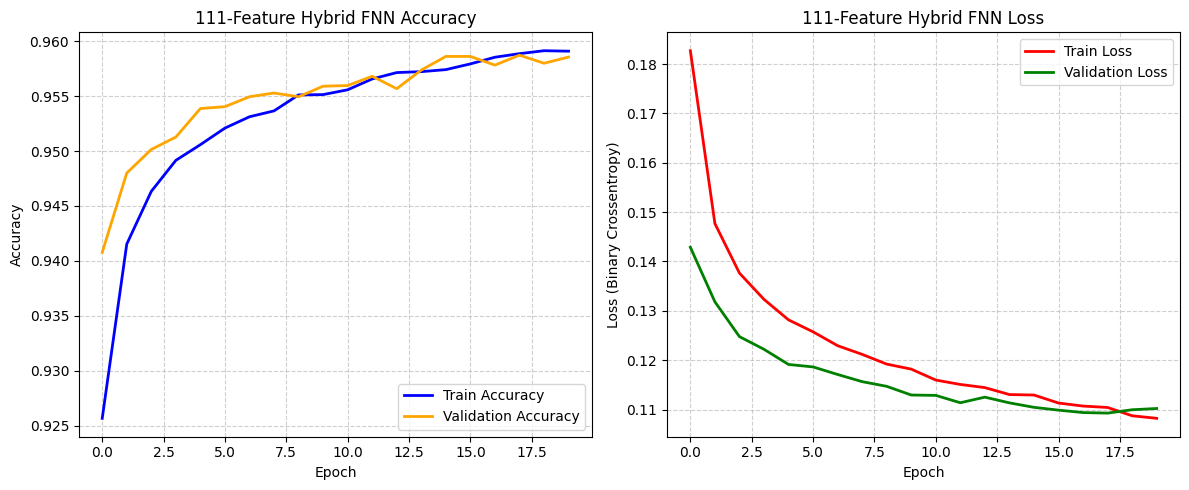

555/555 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


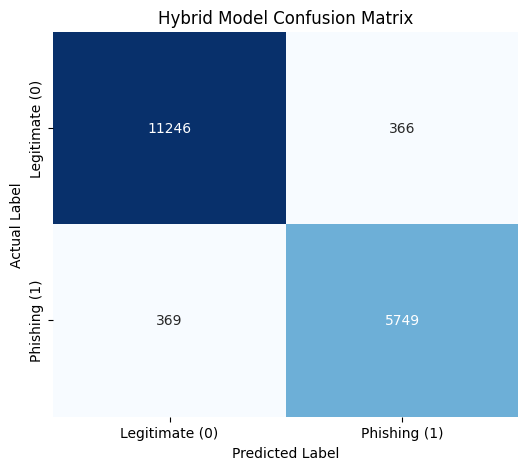


--- 111-FEATURE HYBRID PERFORMANCE METRICS ---
                precision    recall  f1-score   support

Legitimate (0)     0.9682    0.9685    0.9684     11612
  Phishing (1)     0.9401    0.9397    0.9399      6118

      accuracy                         0.9585     17730
     macro avg     0.9542    0.9541    0.9541     17730
  weighted avg     0.9585    0.9585    0.9585     17730



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. PLOT TRAINING AND LOSS CURVES
plt.figure(figsize=(12, 5))

# Accuracy Curve
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
plt.title('111-Feature Hybrid FNN Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

# Loss Curve
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='red', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='green', linewidth=2)
plt.title('111-Feature Hybrid FNN Loss')
plt.ylabel('Loss (Binary Crossentropy)')
plt.xlabel('Epoch')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. GENERATE CONFUSION MATRIX AND METRICS
y_pred_probs = model.predict(X_test_scaled)
y_pred_classes = (y_pred_probs >= 0.50).astype(int)

cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Legitimate (0)', 'Phishing (1)'],
            yticklabels=['Legitimate (0)', 'Phishing (1)'])
plt.title('Hybrid Model Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

print("\n--- 111-FEATURE HYBRID PERFORMANCE METRICS ---")
print(classification_report(y_test, y_pred_classes, target_names=['Legitimate (0)', 'Phishing (1)'], digits=4))

In [ ]:
import pandas as pd

# Load the dataset
url = 'https://raw.githubusercontent.com/biggmanuel/URL-and-Content-Hybrid-Deep/refs/heads/main/dataset_full.csv'
df = pd.read_csv(url)

print(f"Total Columns Verified: {len(df.columns)}")
print(f"Total Samples (Rows): {len(df)}")
print("\nFirst 10 Columns:")
print(df.columns.tolist()[:10])
print("\nLast 10 Columns:")
print(df.columns.tolist()[-10:])

Total Columns Verified: 112
Total Samples (Rows): 88647

First 10 Columns:
['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url']

Last 10 Columns:
['qty_ip_resolved', 'qty_nameservers', 'qty_mx_servers', 'ttl_hostname', 'tls_ssl_certificate', 'qty_redirects', 'url_google_index', 'domain_google_index', 'url_shortened', 'phishing']
